In [1]:
from dataclasses import dataclass
from fractions import Fraction
from functools import reduce
from math import lcm

import numpy as np
import matplotlib.pyplot as plt
import time

import spcm
from spcm import units


plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": False})

from pathlib import Path
import json
import sys
from Equipments.ThorCamLinux import Camera, LiveMonitor, diagnostics, list_cameras, output_path, save_frame
from DataProcessing.TweezerAnalyze import analyze_1D_tweezer_array

# Override the unavailable Times New Roman default set by DataProcessing imports.
plt.rcParams['font.family'] = 'DejaVu Serif'


In [2]:
@dataclass(frozen=True)
class AWGConfig:
    card_resource: str = "/dev/spcm0"
    sample_rate_mhz: int = 625
    segment_alignment_samples: int = 32
    sequence_memory_slots: int = 4
    max_loop_samples: int = 10_000_000

    empty_tone_ramp_us: float = 2.0
    movement_us_per_site: float = 5.0
    minimum_movement_us: float = 2.0
    phase_settle_us: float = 10.0
    phi1_rad: float = 0.0

    dac_headroom: float = 0.85
    dac_max_code: int = 32767
    min_output_range_mv: float = 80.0
    max_output_range_mv: float = 2500.0


@dataclass(frozen=True)
class AWGChannelConfig:
    index: int
    single_tone_amplitude_mv: float
    load_ohm: int
    max_average_output_power_dbm: float = 3


class signal_generator:
    # 1. Shared functions
    def __init__(self, config, channel_configs):
        self.config = config
        self.channel_configs = tuple(sorted(channel_configs, key=lambda ch: ch.index))
        self.length = len(self.channel_configs) # the number of the active channels

    def get_calibrated_relative_amplitude(self, frequency):
        return np.ones_like(frequency)
    # def get_calibrated_relative_amplitude(self, frequency):
    #     RF_cal = np.array([1.17390339, 1.15377789, 0.73555567, 1.12615105, 1.04934377,
    #    0.76386118, 1.10833405, 1.30871756, 0.99397095, 0.86537262,
    #    1.03479027, 0.99421762, 0.95754189, 1.06023761, 1.01616564])**2

    #     RF_freq = np.linspace(95, 105, 15)
    #     frequency = np.asarray(frequency, dtype=float)

    #     return np.interp(frequency, RF_freq, RF_cal[::-1])
    
    def generate_waveform(self,frequencies_mhz, phase0):
        """
        generate the waveform for both static stage and dynamic stage
    
        the frequencies_mhz should be a 2D array, the first index is the tone and the second index is the sample
    
        relative amplitudes calibrated
    
        phase0 is a 1d array that contains the initial phase of the waveform
    
        sample_rate_mhz is the card sample rate
        """
        
        if len(frequencies_mhz) !=len(phase0):
            raise ValueError("The number of phase should match the number of the tones")
            
        increments = 2*np.pi*frequencies_mhz/self.config.sample_rate_mhz
        phase = phase0[:, None] + np.cumsum(np.column_stack([np.zeros(len(phase0)), increments[:, :-1]]), axis=1)
        relative_amplitudes = self.get_calibrated_relative_amplitude(frequencies_mhz)
        waveform = np.sum(relative_amplitudes * np.cos(phase), axis=0)
        phase_next = phase0 + np.sum(increments, axis=1)
        return waveform, phase, phase_next

    def get_output_range_mv(self,waveform, single_tone_amplitude_mv ):
        """
        calculate the channel output range in mV based on the waveform and single tone amplitude

        no worry about the relative amp, because it is counted in the waeform
        """
        
        worst_case_peak_mv = np.max(np.abs(waveform)) * single_tone_amplitude_mv
        output_range_mv = np.ceil(worst_case_peak_mv/self.config.dac_headroom)
        if output_range_mv < self.config.min_output_range_mv:
            raise ValueError("Requested per-tone amplitude is too low")
        if output_range_mv > self.config.max_output_range_mv:
            raise ValueError("Requested per-tone amplitude exceeds the available channel range")
        return output_range_mv

    def convert_waveform_to_dac_samples(self, waveform, single_tone_amplitude_mv, output_range_mv):
        """
        convert the wavefom to 16bit DAC samples. For the entire sequence, the output_range should keep fixed
        """
        
        normalized = np.asarray(waveform)*single_tone_amplitude_mv/output_range_mv
        return np.rint(normalized*self.config.dac_max_code).astype(np.int16)

    # 2. Static signal generation
    def as_exact_mhz(self, value):
        if isinstance(value, Fraction):
            return value
        if isinstance(value, (int, np.integer)):
            return Fraction(int(value))
        if isinstance(value, (float, np.floating)):
            return Fraction(str(float(value)))
        return Fraction(value)

    def equally_spaced_frequencies_mhz(self, start_mhz, stop_mhz, count):
        start = self.as_exact_mhz(start_mhz)
        stop = self.as_exact_mhz(stop_mhz)
        spacing = (stop-start)/(count-1)
        return np.array([start+i*spacing for i in range(count)], dtype=object)

    def generate_exact_frequencies_mhz(self, frequencies: list):
        return np.array([self.as_exact_mhz(f) for f in frequencies], dtype=object)

    def common_phase_period_samples(self, frequencies_mhz, sample_rate_mhz):
        """Return the smallest N for which N*f/fs is integral for every tone."""
        fs = Fraction(sample_rate_mhz)
        denominators = [(self.as_exact_mhz(f)/fs).denominator for f in frequencies_mhz]
        return lcm(*denominators, 1)

    def generate_static_waveform_one_channel(self, frequencies_mhz, start_phases, loop_samples):
        frequency = np.asarray(frequencies_mhz, dtype=float)
        phase0 = np.asarray(start_phases, dtype=float)
    
        frequency_matrix = np.repeat(frequency[:, None], loop_samples, axis=1)
        waveform, phase, phase_next = self.generate_waveform(frequency_matrix, phase0)
        return waveform, phase_next


    def generate_static_signal(self, frequencies_mhz_dict, phases_dict, output_ranges_mv_dict = None):
        if frequencies_mhz_dict.keys() != phases_dict.keys():
            raise ValueError("The frequency, phases channel indices do not match")

        channel_rows_dict = {channel.index: index for index, channel in enumerate(self.channel_configs)} # the dict is like this {0:0,2:1,}, this dict stores the configured channels
        if not frequencies_mhz_dict.keys() <= channel_rows_dict.keys():
            raise ValueError("The frequencies exceed the configured channels")

        initial_sequence = False
        if output_ranges_mv_dict == None:
            initial_sequence = True

        base_periods = []

        # the following code loops all active channels and find the lcm for each channel, then stored in the base_periods
        for active_channel in frequencies_mhz_dict.keys():
            channel_frequencies = frequencies_mhz_dict[active_channel]
            channel_phases = phases_dict[active_channel]
            if channel_frequencies.ndim != 1 or channel_phases.ndim != 1:
                raise ValueError("Each channel must contain one-dimensional tone arrays")
            if len(channel_frequencies) != len(channel_phases):
                raise ValueError(f"CH{active_channel} frequency, phases counts do not match")
            exact_frequencies = np.array([self.as_exact_mhz(f) for f in channel_frequencies])
            base_period = self.common_phase_period_samples(exact_frequencies, self.config.sample_rate_mhz)
            base_periods.append(base_period)
            
        # find the common lcm for all active channels
        loop_samples = lcm(*base_periods, self.config.segment_alignment_samples)
        if loop_samples > self.config.max_loop_samples:
            raise ValueError("Static hold period exceeds max_loop_samples")

        #this should be a rectangular since the segments for all channels should align. The first index also cover all configured channels
        samples_matrix = np.zeros((self.length, loop_samples), dtype=np.int16) # shape: number of configured channels * sample length
        if initial_sequence:
            output_ranges_mv_dict = {configured_channel.index: self.config.min_output_range_mv for configured_channel in self.channel_configs} # shape: number of configured channels
        phases_next_dict = {active_channel: np.zeros(0) for active_channel in frequencies_mhz_dict.keys()} # shape: number of configured channels, for each key, the value is an array with the size of number of tones

        # the following code loop the active channels and update the samples and output ranges
        for active_channel in frequencies_mhz_dict.keys():
            waveform, phase_next = self.generate_static_waveform_one_channel(frequencies_mhz_dict[active_channel], phases_dict[active_channel], loop_samples)
            phases_next_dict[active_channel] = phase_next

            single_tone_amplitude_mv = self.channel_configs[channel_rows_dict[active_channel]].single_tone_amplitude_mv
            
            if initial_sequence:
                output_range_mv = self.get_output_range_mv(waveform, single_tone_amplitude_mv)
            else:
                output_range_mv = output_ranges_mv_dict[active_channel]
                
            samples = self.convert_waveform_to_dac_samples(waveform, single_tone_amplitude_mv, output_range_mv)
            output_ranges_mv_dict[active_channel] = output_range_mv
            samples_matrix[channel_rows_dict[active_channel]] = samples

        return samples_matrix, output_ranges_mv_dict, frequencies_mhz_dict, phases_next_dict

        
    # 2.1 initial equal spacing static signal generation
    def generate_initial_phases(self, frequencies, phi1=0.0):
        amplitudes = self.get_calibrated_relative_amplitude(frequencies)
        powers = amplitudes**2/np.sum(amplitudes**2)
        phases = np.zeros(len(amplitudes))
        phases[0] = phi1
        for m in range(1, len(amplitudes)):
            phases[m] = phi1 + 2*np.pi*sum((m-i)*powers[i] for i in range(m))
        return np.mod(phases, 2*np.pi)

    # 3. dynamic signal generation
    def find_target_position(self, initial_occupancy):
        position = np.flatnonzero(initial_occupancy)
        n = len(initial_occupancy)
        m = len(position)
        candidates = [np.arange(m) + i for i in range(n - m + 1)]
        distances = [np.sum(np.abs(position - c)) for c in candidates]
        return {"start": position, "target": candidates[np.argmin(distances)]}
    
    def transfer_function(self, s):
        return 10*s**3 - 15*s**4 + 6*s**5

    
    def generate_dynamic_waveform_one_channel(self, start_frequencies_mhz, start_phases, occupancy_list: list, target_occupancy_list: list, n_samples: float):

        # print(start_frequencies_mhz)
        if len(start_frequencies_mhz) != len(start_phases):
            raise ValueError("the lens of the start frequencies doesn't match the start phases")
        if len(occupancy_list) != len(target_occupancy_list):
            raise ValueError("the occupancy lists do not match")

            
        s = np.linspace(0.0, 1.0, n_samples)
        h = self.transfer_function(s)
        start_frequencies_occupancy = np.asarray(start_frequencies_mhz[occupancy_list], dtype=float)
        start_phases_occupancy = start_phases[occupancy_list]
        end_frequencies_occupancy = np.asarray(start_frequencies_mhz[target_occupancy_list], dtype=float)
        end_frequencies_occupancy_exact = start_frequencies_mhz[target_occupancy_list] # used as the return
        
        frequency_trajectory_matrix = np.array(start_frequencies_occupancy[:,None] * (1-h) + end_frequencies_occupancy[:,None] * h, dtype = float)

        waveform, phase, phase_next = self.generate_waveform(frequency_trajectory_matrix, start_phases_occupancy)

        return waveform, end_frequencies_occupancy_exact, phase_next

    def generate_dynamic_signal(self, start_frequencies_mhz_dict, movement_pair_dict, start_phases_dict, output_ranges_mv_dict, duration_us):
        """
        movement_pair_dict is a nested dictionary{channel number: {"start":list of the occupancy, "target": list of the target occupancy}}
        """
        if start_frequencies_mhz_dict.keys() != start_phases_dict.keys():
            raise ValueError("The frequency, phases channel indices do not match")

        channel_rows_dict = {channel.index: index for index, channel in enumerate(self.channel_configs)} # the dict is like this {0:0,2:1,}, this dict stores the configured channels
        if not start_frequencies_mhz_dict.keys() <= channel_rows_dict.keys():
            raise ValueError("The frequencies exceed the configured channels")
        if not movement_pair_dict.keys() <= start_frequencies_mhz_dict.keys():
            raise ValueError("The dynamic channel is out of the active channels")

        # for current dynamic frequency transfer, just find the lcm of duration and 32
        raw_samples = duration_us * self.config.sample_rate_mhz                      
        n_samples = self.config.segment_alignment_samples * int(np.ceil(raw_samples/self.config.segment_alignment_samples))
        
        #this should be a rectangular since the segments for all channels should align. The first index also cover all configured channels
        samples_matrix = np.zeros((self.length, n_samples), dtype=np.int16) # shape: number of configured channels * sample length
        phases_next_dict = {active_channel: np.zeros(0) for active_channel in start_frequencies_mhz_dict.keys()} # shape: number of configured channels, for each key, the value is an array with the size of number of tones
        frequencies_next_mhz_dict = start_frequencies_mhz_dict.copy()
        
        # the following code loop the active channels and update the samples and next phases. 
        # Here I iterate the frequencies dict instead of the movement pair is due to some channels may not move
        for active_channel in start_frequencies_mhz_dict.keys():
            single_tone_amplitude_mv = self.channel_configs[channel_rows_dict[active_channel]].single_tone_amplitude_mv
            output_range_mv = output_ranges_mv_dict[active_channel]
            if active_channel in movement_pair_dict:
                waveform, frequency_next, phase_next = self.generate_dynamic_waveform_one_channel(start_frequencies_mhz_dict[active_channel], start_phases_dict[active_channel], 
                                                                                  movement_pair_dict[active_channel]["start"], 
                                                                                  movement_pair_dict[active_channel]["target"], n_samples)
                
                
                
                samples = self.convert_waveform_to_dac_samples(waveform, single_tone_amplitude_mv, output_range_mv)
                samples_matrix[channel_rows_dict[active_channel]] = samples
                phases_next_dict[active_channel] = phase_next
                frequencies_next_mhz_dict[active_channel] = frequency_next

                
            else:
                waveform, phase_next = self.generate_static_waveform_one_channel(start_frequencies_mhz_dict[active_channel], start_phases_dict[active_channel], n_samples)
                phases_next_dict[active_channel] = phase_next
                samples = self.convert_waveform_to_dac_samples(waveform, single_tone_amplitude_mv, output_range_mv)
                samples_matrix[channel_rows_dict[active_channel]] = samples
                
        return samples_matrix, output_ranges_mv_dict, frequencies_next_mhz_dict, phases_next_dict
        
        
        

In [3]:
class AWG_sequence_mode:
    """Experiment-level sequence orchestration built on official spcm objects."""

    def __init__(self, config, channel_configs, verbose=False):
        self.config = config
        self.channel_configs = tuple(sorted(channel_configs, key=lambda ch: ch.index))
        self.verbose = verbose
        self.card = None
        self.channels = None
        self.sequence = None
        
        self.initial_segment = None
        self.dynamic_segment = None
        self.final_segment = None
        
        self.initial_step = None
        self.dynamic_step = None
        self.final_step = None

    def __enter__(self):
        return self.open()

    def __exit__(self, exc_type, exc_value, traceback):
        self.close()
        return False

    def open(self):
        """
        open the card the configed channels.

        set up the sequence mode
        """
        if self.card is None:
            self.card = spcm.Card(self.config.card_resource, verbose=self.verbose)
            self.card.open()
            self.card.card_mode(spcm.SPC_REP_STD_SEQUENCE)
    
            clock = spcm.Clock(self.card)
            clock.sample_rate(self.config.sample_rate_mhz*units.MHz)
            clock.clock_output(False)
    
            trigger = spcm.Trigger(self.card)
            trigger.or_mask(spcm.SPC_TMASK_NONE)  # Startup uses one software force trigger.
    
            # One channel is used now. OR-ing channel constants makes the same code ready for CH1 later.
            channel_constants = (spcm.CHANNEL0, spcm.CHANNEL1, spcm.CHANNEL2, spcm.CHANNEL3)
            channel_mask = 0
            for channel_config in self.channel_configs:
                channel_mask |= channel_constants[channel_config.index]
            self.channels = spcm.Channels(self.card, card_enable=channel_mask)
    
            # spcm.Channels stores enabled channels in ascending physical-channel order.
            for index, channel_config in enumerate(self.channel_configs):
                hardware_channel = self.channels[index]
                hardware_channel.enable(True)
                hardware_channel.output_load(channel_config.load_ohm * units.ohm)
                hardware_channel.amp(self.config.min_output_range_mv * units.mV)
                hardware_channel.stop_level(spcm.SPCM_STOPLVL_HOLDLAST)
    
            self.sequence = spcm.Sequence(self.card)

        # This partitions physical onboard memory into four equal slots before playback.
            self.sequence.max_segments(self.config.sequence_memory_slots)
            return self

    def setup_initial_sequence(self, sample_matrix, output_range_mv_dict):
        """
        if there are more than one channel, the sample length for all channels should be the same in one replay segment
        """
        #check if the sample_matrix is 2D
        if sample_matrix.ndim != 2:
            raise ValueError("The dimension of the sample_matrix 2")
        if len(sample_matrix) != len(output_range_mv_dict) or len(sample_matrix) != len(self.channel_configs):
            raise ValueError("the sample matrix and the output range should cover all configured channels")
            
        
        # Set up the output range and check the power
        for index, configured_channel in enumerate(self.channel_configs):
            output_range_mv = output_range_mv_dict[configured_channel.index]
            self.channels[index].amp(int(output_range_mv))
            if sample_matrix[index].all() == 0:
                continue
            power_dbm = self.compute_awg_output_power(sample_matrix[index] , output_range_mv)
            if power_dbm > self.channel_configs[index].max_average_output_power_dbm:
                raise ValueError(f"Predicted power {power_dbm:.3f} dBm exceeds limit")

        # Segment index 0 is the only waveform transferred before the camera cycle starts.
        self.initial_segment = self.sequence.add_segment(sample_matrix.shape[1])
        self.initial_segment[:, :] = sample_matrix
        self.sequence.transfer_segment(self.initial_segment)
        
        # initial re-enters itself after each complete initial segment.
        self.initial_step = self.sequence.add_step(self.initial_segment, loops=1)
        self.initial_step.set_transition(self.initial_step)
        self.initial_step.update()

        self.sequence.entry_step(self.initial_step)

    def start_initial_hold(self):
        # This is the experiment's only trigger. Subsequent switching uses step-memory updates.
        self.initial_step.update(to_step=self.initial_step)
        self.card.start(spcm.M2CMD_CARD_ENABLETRIGGER, spcm.M2CMD_CARD_FORCETRIGGER,)

    def setup_dynamic_sequence(self, dynamic_matrix, final_matrix):
        if dynamic_matrix.ndim != 2 or final_matrix.ndim != 2:
            raise ValueError("The dimension of the sample_matrix 2")
        if len(dynamic_matrix) != len(self.channel_configs):
            raise ValueError("the sample matrix and the output range should cover all configured channels")

        # Prepare inactive waveform segments
        self.dynamic_segment = self.sequence.add_segment(dynamic_matrix.shape[1])
        self.dynamic_segment[:, :] = dynamic_matrix

        self.final_segment = self.sequence.add_segment(final_matrix.shape[1])
        self.final_segment[:, :] = final_matrix

        # DMA only inactive waveform slots
        self.sequence.transfer_segment(self.dynamic_segment)
        self.sequence.transfer_segment(self.final_segment)

        # Prepare downstream sequence
        self.dynamic_step = self.sequence.add_step(self.dynamic_segment,loops=1)

        self.final_step = self.sequence.add_step(self.final_segment, loops=1)

        # FINAL -> FINAL
        self.final_step.set_transition(self.final_step)
        self.final_step.update()
    
        # MOVE -> FINAL
        self.dynamic_step.set_transition(self.final_step)
        self.dynamic_step.update()

    def commit_rearrangement(self):
    
        # Atomic logical commit:
        # INITIAL -> MOVE
        self.initial_step.update(to_step=self.dynamic_step)
        
    def current_step(self):
        return self.sequence.current_step()

    def stop(self):
        if self.card is not None:
            self.card.stop()

    def close(self):
        if self.card is not None:
            try:
                self.card.stop()
            finally:
                self.card.close()
                self.card = None
                
    def clear(self):
        if self.card is not None:
            self.card.stop()
            self.sequence = spcm.Sequence(self.card)
            self.sequence.max_segments(self.config.sequence_memory_slots)

    # power check
    def compute_awg_output_power(self, samples_one_channel, output_range_mv):
        """Predict average, load power from the exact DAC samples and fixed card range."""
        voltage_v = samples_one_channel / self.config.dac_max_code * output_range_mv/1000
        vrms_v = np.sqrt(np.mean(voltage_v**2))
        power_mw = 1000*vrms_v**2/50
        power_dbm = 10*np.log10(power_mw)
        return power_dbm

# AOD feedback


In [4]:
CFG = AWGConfig()
CH0CFG = AWGChannelConfig(index=0, single_tone_amplitude_mv = 80, load_ohm=50)
SG = signal_generator(CFG,[CH0CFG])


In [5]:
AWG = AWG_sequence_mode(CFG,[CH0CFG])

In [6]:
AWG.open()

In [14]:
AWG.stop()

In [15]:
AWG.clear()

In [16]:
AWG.close()

### config camera

In [7]:
SAVE_DIRECTORY = Path('./camera_data/AOD calibration').resolve()
EXPOSURE_US = 1
SERIAL = None
serials = list_cameras()
print('Detected serials:', serials)
camera = Camera(SERIAL)
print('Connected:', camera.serial)


Detected serials: ['33834']
Connected: 33834


In [13]:
if monitor is not None:
    monitor.close()
    monitor = None
if camera is not None:
    camera.close()
    camera = None
print('Camera and monitor closed.')


Camera and monitor closed.


In [8]:
monitor = LiveMonitor(camera, directory=SAVE_DIRECTORY, preview_fps=8)
monitor.exposure.value = EXPOSURE_US
monitor.show()

In [56]:
frame = camera.capture(exposure_us=EXPOSURE_US, timeout_s=3)
image_float = frame.image.astype('float64')

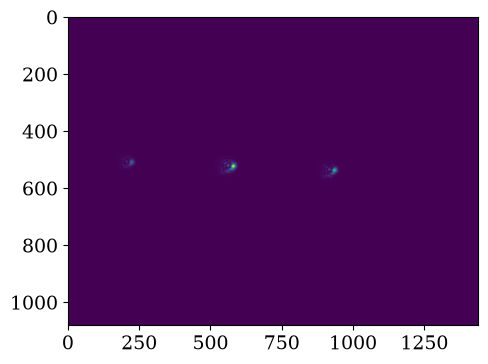

In [57]:
plt.imshow(image_float)

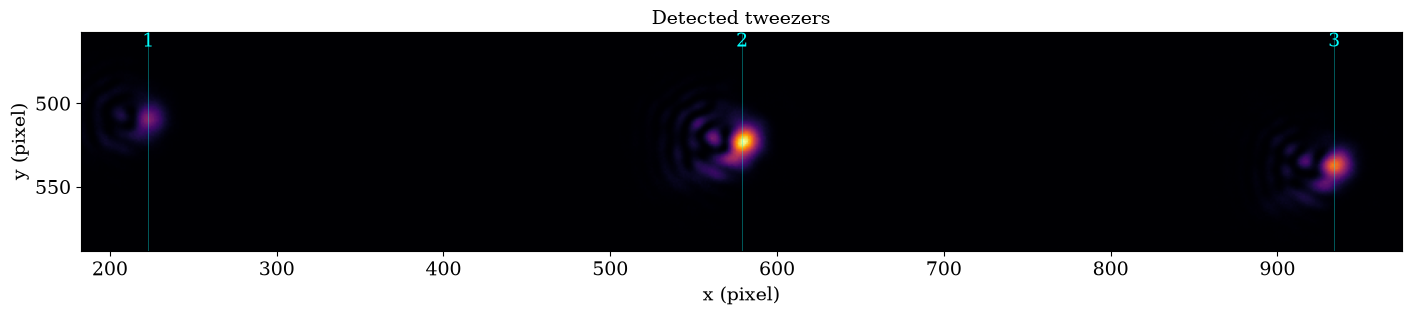

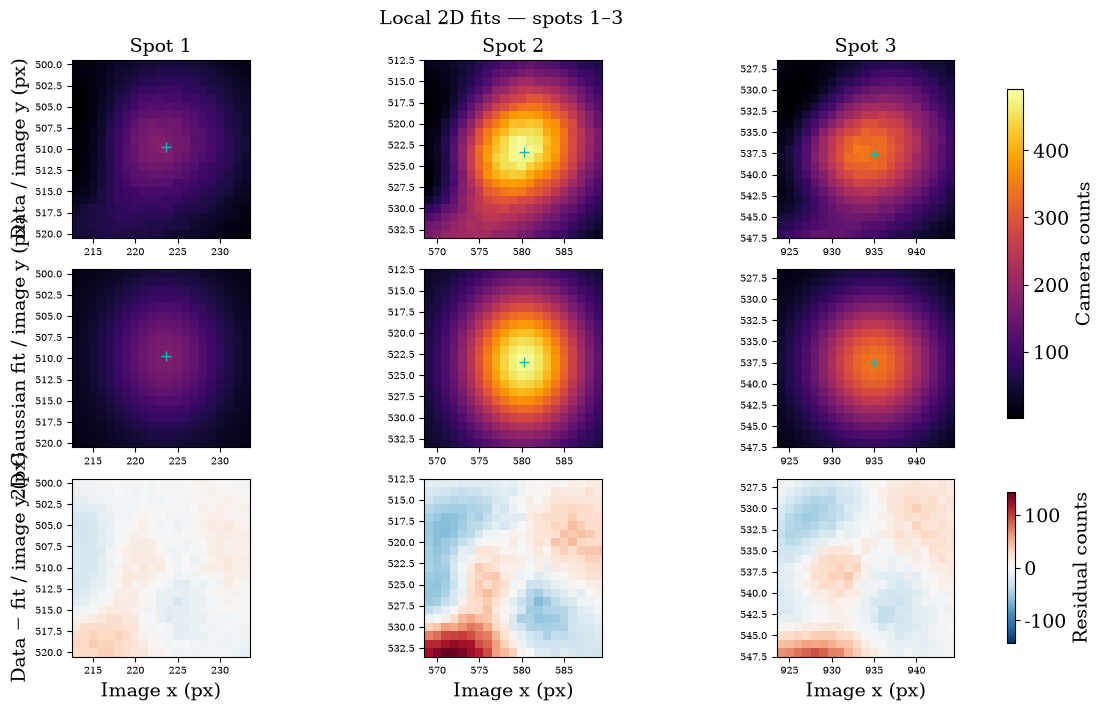

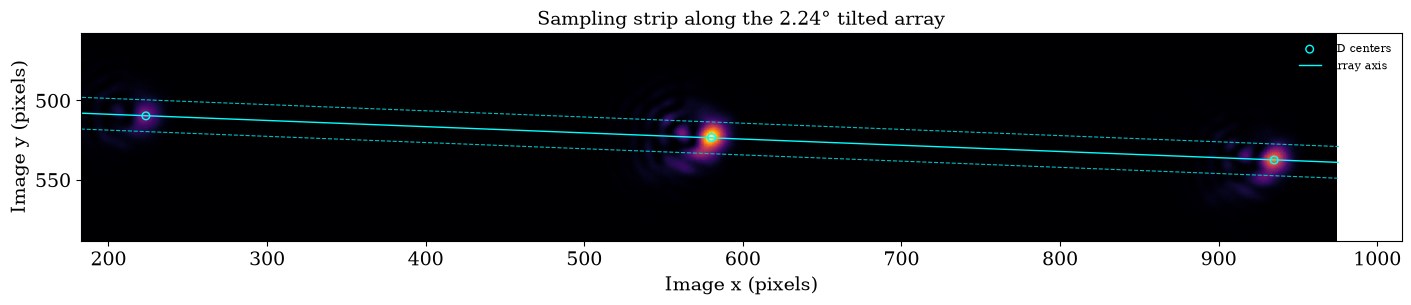

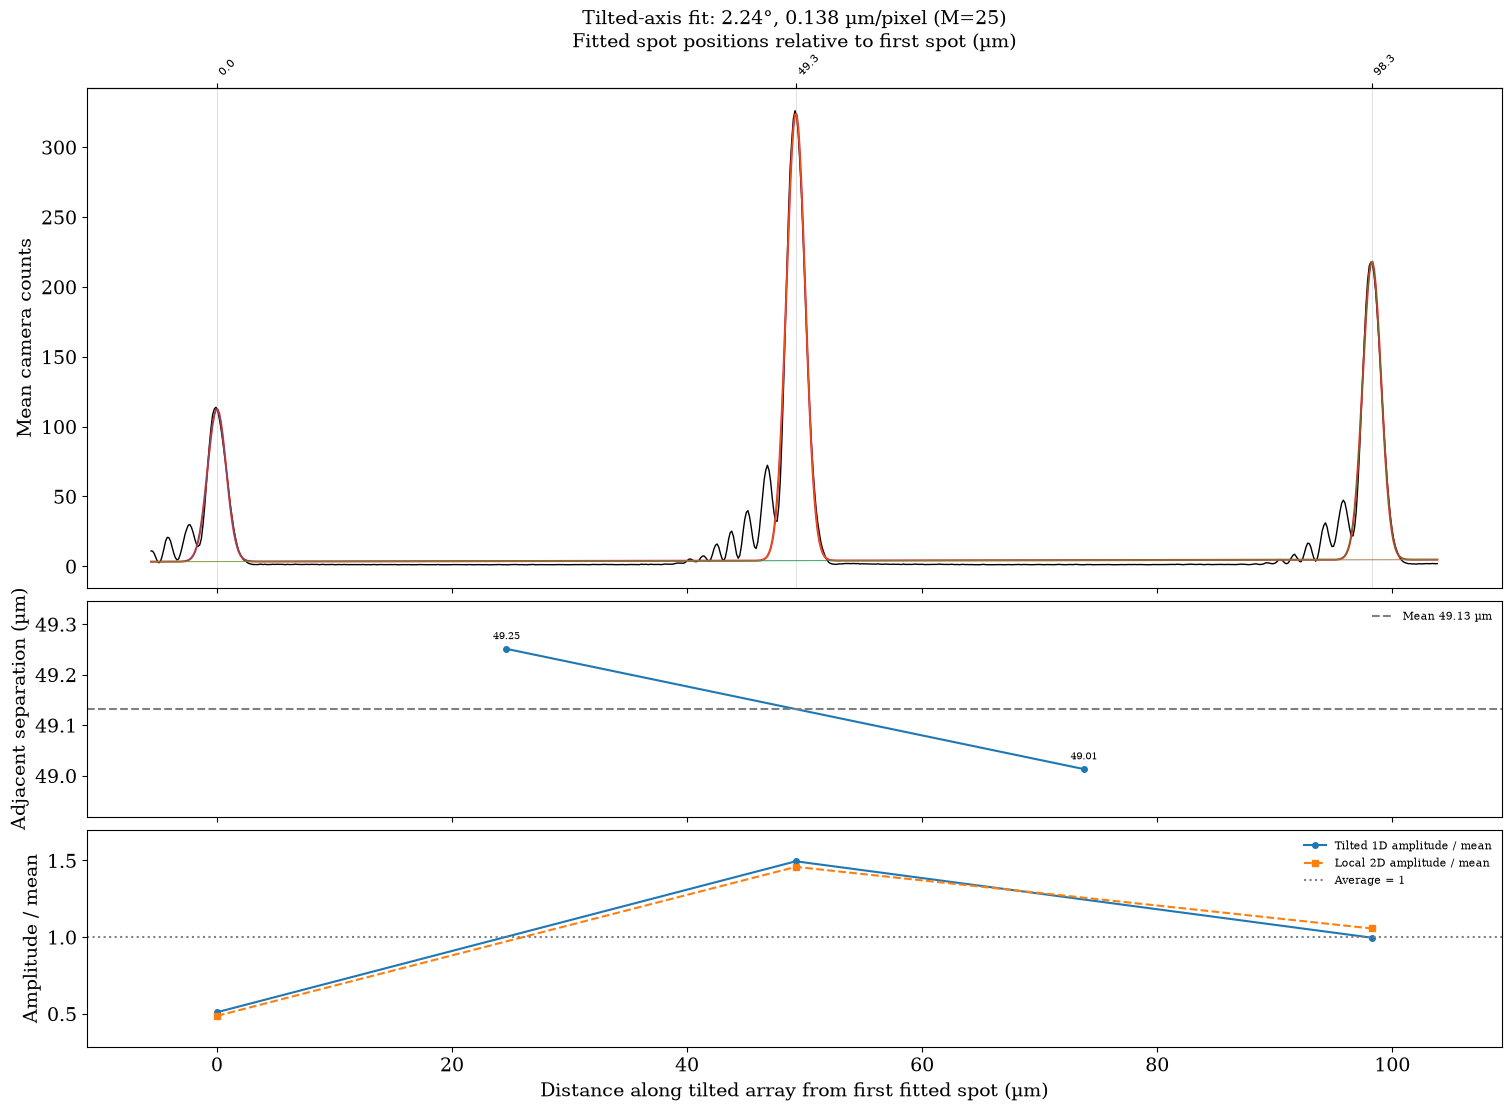

In [58]:
results = analyze_1D_tweezer_array(image_float,n_spots=3,fit_config= {"min_peak_distance":10},plot=True)

## AOD RF-laser power response

In [9]:
CH0_INITIAL_FREQUENCIES_MHZ = SG.equally_spaced_frequencies_mhz(95, 105, 3)
# CH0_INITIAL_FREQUENCIES_MHZ = SG.generate_exact_frequencies_mhz([95])

In [10]:
CH0_INITIAL_RELATIVE_AMPLITUDES = np.ones(len(CH0_INITIAL_FREQUENCIES_MHZ))
# CH0_INITIAL_RELATIVE_AMPLITUDES = SG.get_calibrated_relative_amplitude(CH0_INITIAL_FREQUENCIES_MHZ)
CH0_INITIAL_PHASES = SG.generate_initial_phases(CH0_INITIAL_RELATIVE_AMPLITUDES)
initial_samples_matrix, output_ranges, initial_frequencies_next_mhz, initial_phases_next = SG.generate_static_signal({0: CH0_INITIAL_FREQUENCIES_MHZ}, {0:CH0_INITIAL_PHASES})

In [11]:
s = time.time()
AWG.setup_initial_sequence(initial_samples_matrix, output_ranges)
e = time.time()
e-s

0.002115964889526367

In [12]:
AWG.start_initial_hold()

In [59]:
RF_relative_amplitude_list = np.linspace(0.5,1.5,101)
for relative_amp in RF_relative_amplitude_list:
    CH0_INITIAL_RELATIVE_AMPLITUDES_C = np.ones(len(CH0_INITIAL_FREQUENCIES_MHZ))
    CH0_INITIAL_PHASES_C = SG.generate_initial_phases(CH0_INITIAL_RELATIVE_AMPLITUDES_C)
    initial_samples_matrix, output_ranges, initial_frequencies_next_mhz, initial_phases_next = SG.generate_static_signal({0: CH0_INITIAL_FREQUENCIES_MHZ}, {0:CH0_INITIAL_PHASES_C})

array([0.5 , 0.51, 0.52, 0.53, 0.54, 0.55, 0.56, 0.57, 0.58, 0.59, 0.6 ,
       0.61, 0.62, 0.63, 0.64, 0.65, 0.66, 0.67, 0.68, 0.69, 0.7 , 0.71,
       0.72, 0.73, 0.74, 0.75, 0.76, 0.77, 0.78, 0.79, 0.8 , 0.81, 0.82,
       0.83, 0.84, 0.85, 0.86, 0.87, 0.88, 0.89, 0.9 , 0.91, 0.92, 0.93,
       0.94, 0.95, 0.96, 0.97, 0.98, 0.99, 1.  , 1.01, 1.02, 1.03, 1.04,
       1.05, 1.06, 1.07, 1.08, 1.09, 1.1 , 1.11, 1.12, 1.13, 1.14, 1.15,
       1.16, 1.17, 1.18, 1.19, 1.2 , 1.21, 1.22, 1.23, 1.24, 1.25, 1.26,
       1.27, 1.28, 1.29, 1.3 , 1.31, 1.32, 1.33, 1.34, 1.35, 1.36, 1.37,
       1.38, 1.39, 1.4 , 1.41, 1.42, 1.43, 1.44, 1.45, 1.46, 1.47, 1.48,
       1.49, 1.5 ])

59.84325289726257

In [6]:
initial

array([1., 0., 1., 0., 0., 0., 1., 1., 0., 0., 1., 0.])

In [129]:
final_samples_matrix, output_ranges, final_frequencies_next_mhz, final_phases_next = SG.generate_static_signal(dynamic_frequencies_next_mhz, dynamic_phases_next, output_ranges)

0.001514434814453125

In [130]:
s = time.time()
AWG.setup_dynamic_sequence(dynamic_samples_matrix, final_samples_matrix)
e = time.time()
e-s

0.2870032787322998

In [131]:
AWG.commit_rearrangement()

In [ ]:
from Equipments.ThorCamLinux import Camera
from DataProcessing.TweezerAnalyze import analyze_1D_tweezer_array

RUN_FEEDBACK = False
N_TONES = 25
NUM_UPDATES = 2
GAIN = 0.5
EXPOSURE_US = 1

# Entry j is the camera spot index for RF tone j (camera spots run left to right).
TONE_TO_SPOT = np.arange(N_TONES)        # if frequency increases left to right


In [ ]:

if len(AWG.channel_configs) != 1 or AWG.channel_configs[0].index != 0 or AWG.channel_configs[0].load_ohm != 50:
    raise ValueError('Use a single CH0 configured for a 50-ohm load.')
tone_order = np.asarray(TONE_TO_SPOT)
if tone_order.shape != (N_TONES,) or tone_order.dtype.kind not in 'iu' or not np.array_equal(np.sort(tone_order), np.arange(N_TONES)):
    raise ValueError('Set TONE_TO_SPOT to the confirmed spot-to-tone mapping.')
if not isinstance(NUM_UPDATES, int) or NUM_UPDATES < 0 or not 0 < GAIN <= 1:
    raise ValueError('Use NUM_UPDATES >= 0 and 0 < GAIN <= 1.')

SG = signal_generator(AWG.config, AWG.channel_configs)
frequencies = SG.equally_spaced_frequencies_mhz(95, 105, N_TONES)
amplitudes = np.ones(N_TONES)
phases = SG.generate_initial_phases(frequencies)

try:
    for turn in range(NUM_UPDATES + 1):
        # Make the generator use the current voltage-amplitude calibration.
        SG.get_calibrated_relative_amplitude = lambda f, a=amplitudes.copy(), rf=np.asarray(frequencies, dtype=float): np.interp(np.asarray(f, dtype=float), rf, a)
        samples, ranges, _, _ = SG.generate_static_signal({0: frequencies}, {0: phases})
        power_dbm = AWG.compute_awg_output_power(samples[0], ranges[0])
        if not np.isfinite(power_dbm) or power_dbm > AWG.channel_configs[0].max_average_output_power_dbm:
            raise ValueError('Updated waveform exceeds the RF-power limit.')
        AWG.clear()
        AWG.setup_initial_sequence(samples, ranges)
        AWG.start_initial_hold()
        time.sleep(0.2)

        frame = camera.capture(exposure_us=EXPOSURE_US, timeout_s=3)
        if np.any(frame.image >= (1 << frame.bit_depth) - 1):
            raise RuntimeError('Camera saturated: reduce exposure.')
        result = analyze_1D_tweezer_array(frame.image, n_spots=N_TONES, plot=True)
        if result['quality_issues'] or not np.isfinite(result['r_squared']) or result['r_squared'] < 0.9:
            raise RuntimeError('Inspect the image/fit before applying feedback.')
        ratios = result['intensity_ratio'][tone_order]
        print(f'Turn {turn}: max intensity error = {np.max(np.abs(ratios - 1)):.2%}')

        # No correction after the last image: it verifies the final waveform.
        if turn < NUM_UPDATES:
            amplitudes = amplitudes * ratios ** (-GAIN / 2)
except BaseException:
    AWG.stop()
    raise

print('Final relative voltage amplitudes:', amplitudes)
    # SG retains this calibration. Regenerate any old waveform matrices before reuse.

